In [1]:
# CA1 – Business Analytics: Tasks 1
# Scope: Task 1 (Retail Performance Analytics)
# Scenario: Operations Director
# Dependencies: pandas, numpy, matplotlib, seaborn, sklearn
# Bash:python -m pip install numpy pandas scikit-learn matplotlib seaborn

In [2]:
# Import necessary libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load the retail data
df = pd.read_csv("../Data/Retail_regions.csv")

# 2. Inspect the data and check its quality
print("First five rows:")
print(df.head())
print("\nDataset size:", df.shape)
print("\nMissing values per column:")
print(df.isnull().sum())
print("\nExact duplicate rows:", df.duplicated().sum())

First five rows:
   StoreID Region    StoreType  MarketingSpend     Footfall  OnlineTraffic  \
0     1030  South  Retail Park     5216.025748  1360.669726   15143.645217   
1     1013  North         Town     2589.258613  1759.537410    9575.301668   
2     1022  North  Retail Park     5236.467946  1444.458541            NaN   
3     1094  North         Mall     5848.627748  1369.644357    6489.545492   
4     1037  North  Retail Park     6647.672155  1073.218324   13003.156557   

   StaffHours  DiscountRate  CustomerSatisfaction  InventoryAvailability  \
0  274.440248     24.246254             84.013149              83.191515   
1  354.439564     33.884441             76.316110              86.923332   
2  343.287855     37.862522             79.487759              90.428512   
3  408.194166     23.574998             63.922735              80.859629   
4  390.722992      4.795855             58.007873              94.395740   

   CompetitorDistance  PreviousMonthSales  Season  SalesR

In [3]:
# Remove exact duplicate rows
df = df.drop_duplicates()

# Fill missing numeric values with the column median.
for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())
    
# Fill missing text values with the most common value (mode).
for col in df.select_dtypes(include="object").columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].mode()[0])

C:\Users\eunix\AppData\Local\Temp\ipykernel_32752\2679499561.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


In [4]:
# 3. Investigate possible outliers using the IQR rule.
# This counts unusual values; it does not automatically delete them.
for col in df.select_dtypes(include="number").columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    count = ((df[col] < q1 - 1.5 * iqr) |
             (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"Possible outliers in {col}: {count}")

Possible outliers in StoreID: 0
Possible outliers in MarketingSpend: 123
Possible outliers in Footfall: 43
Possible outliers in OnlineTraffic: 69
Possible outliers in StaffHours: 33
Possible outliers in DiscountRate: 0
Possible outliers in CustomerSatisfaction: 61
Possible outliers in InventoryAvailability: 29
Possible outliers in CompetitorDistance: 0
Possible outliers in PreviousMonthSales: 47
Possible outliers in SalesRevenue: 30


In [5]:
# 4. Create at least three useful features

# Revenue per visitor helps compare stores of different sizes.
df["RevenuePerVisitor"] = df["SalesRevenue"] / df["Footfall"].replace(0, pd.NA)

# Marketing spend as a percentage of revenue
df["MarketingSpendPct"] = (
    df["MarketingSpend"] / df["SalesRevenue"].replace(0, pd.NA) * 100
)

# Compare current revenue with previous month's sales
df["SalesChange"] = df["SalesRevenue"] - df["PreviousMonthSales"]

print("\nSummary statistics:")
print(df.select_dtypes(include="number").describe())


Summary statistics:
           StoreID  MarketingSpend     Footfall  OnlineTraffic   StaffHours  \
count  5000.000000     5000.000000  5000.000000    5000.000000  5000.000000   
mean   1049.683800     5369.788297  1203.245095    8522.728163   348.599130   
std      28.814987     4043.467484   350.373303    2397.776629    79.999497   
min    1000.000000      250.000000   100.000000     500.000000    53.587999   
25%    1024.000000     4117.586403   972.992784    6963.459427   294.399284   
50%    1050.000000     5024.281547  1201.850946    8518.683811   348.190767   
75%    1075.000000     5933.222202  1435.441321    9991.356759   403.325758   
max    1099.000000    65814.623356  2540.423760   17781.988363   651.294406   

       DiscountRate  CustomerSatisfaction  InventoryAvailability  \
count   5000.000000           5000.000000            5000.000000   
mean      19.992814             75.151361              84.997296   
std       11.565196              9.545787               7.49586

In [6]:
# 5. Four GroupBy analyses
print("\nAverage revenue by region:")
print(df.groupby("Region")["SalesRevenue"].mean().sort_values(ascending=False))

print("\nAverage revenue by store type:")
print(df.groupby("StoreType")["SalesRevenue"].mean().sort_values(ascending=False))

print("\nAverage revenue by season:")
print(df.groupby("Season")["SalesRevenue"].mean().sort_values(ascending=False))

print("\nAverage revenue by region and season:")
print(df.groupby(["Region", "Season"])["SalesRevenue"].mean().round(2))


Average revenue by region:
Region
South    155202.315192
West     153226.542019
East     149796.287125
North    149098.073776
Name: SalesRevenue, dtype: float64

Average revenue by store type:
StoreType
Town           152393.317247
Mall           151652.770354
Retail Park    151236.965489
Name: SalesRevenue, dtype: float64

Average revenue by season:
Season
Summer    152394.995146
Spring    151622.237104
Autumn    151602.756535
Winter    151389.669400
Name: SalesRevenue, dtype: float64

Average revenue by region and season:
Region  Season
East    Autumn    151858.52
        Spring    148435.67
        Summer    150082.55
        Winter    148750.33
North   Autumn    148679.98
        Spring    148248.79
        Summer    149882.32
        Winter    149604.50
South   Autumn    153929.66
        Spring    155528.94
        Summer    155879.67
        Winter    155583.68
West    Autumn    151946.76
        Spring    154668.29
        Summer    154088.83
        Winter    152160.01
Name: 

In [7]:
# 6. Two pivot tables
region_pivot = pd.pivot_table(
    df, values="SalesRevenue", index="Region", columns="Season", aggfunc="mean"
)
print("\nPivot table: average revenue by region and season")
print(region_pivot.round(2))

store_pivot = pd.pivot_table(
    df, values="SalesRevenue", index="StoreType", columns="Season", aggfunc="mean"
)
print("\nPivot table: average revenue by store type and season")
print(store_pivot.round(2))



Pivot table: average revenue by region and season
Season     Autumn     Spring     Summer     Winter
Region                                            
East    151858.52  148435.67  150082.55  148750.33
North   148679.98  148248.79  149882.32  149604.50
South   153929.66  155528.94  155879.67  155583.68
West    151946.76  154668.29  154088.83  152160.01

Pivot table: average revenue by store type and season
Season          Autumn     Spring     Summer     Winter
StoreType                                              
Mall         151464.24  151692.55  152447.47  150936.40
Retail Park  150239.80  151451.92  151985.90  151225.43
Town         153085.91  151709.08  152754.18  152036.11


In [8]:
# 7. Correlation with SalesRevenue
numeric_df = df.select_dtypes(include="number")
correlations = numeric_df.corr(numeric_only=True)["SalesRevenue"].sort_values(ascending=False)
print("\nVariables most correlated with SalesRevenue:")
print(correlations)


Variables most correlated with SalesRevenue:
SalesRevenue             1.000000
SalesChange              0.907985
StaffHours               0.576092
Footfall                 0.411688
InventoryAvailability    0.295949
MarketingSpend           0.036257
DiscountRate             0.024228
OnlineTraffic            0.006333
StoreID                  0.004211
CompetitorDistance       0.001689
PreviousMonthSales      -0.007978
CustomerSatisfaction    -0.013051
RevenuePerVisitor       -0.063962
MarketingSpendPct       -0.136658
Name: SalesRevenue, dtype: float64


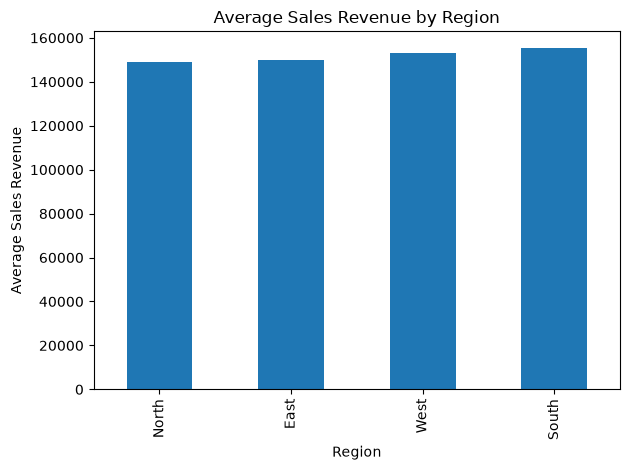

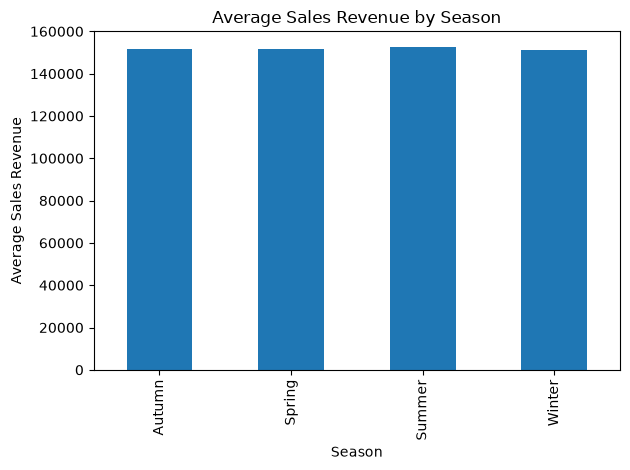

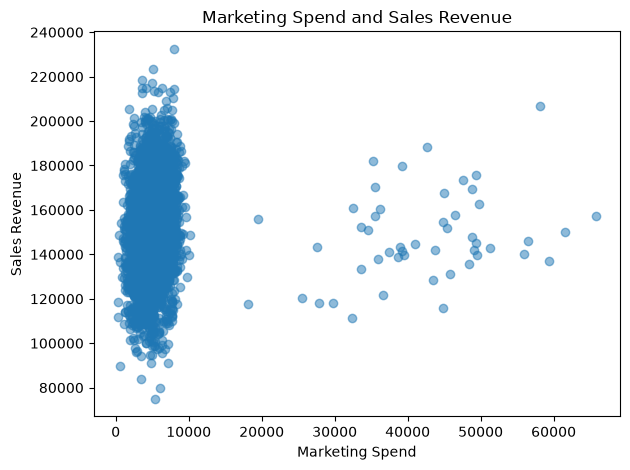

In [9]:
# 8. Create three charts
df.groupby("Region")["SalesRevenue"].mean().sort_values().plot(kind="bar")
plt.title("Average Sales Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Average Sales Revenue")
plt.tight_layout()
plt.show()

df.groupby("Season")["SalesRevenue"].mean().plot(kind="bar")
plt.title("Average Sales Revenue by Season")
plt.xlabel("Season")
plt.ylabel("Average Sales Revenue")
plt.tight_layout()
plt.show()

plt.scatter(df["MarketingSpend"], df["SalesRevenue"], alpha=0.5)
plt.title("Marketing Spend and Sales Revenue")
plt.xlabel("Marketing Spend")
plt.ylabel("Sales Revenue")
plt.tight_layout()
plt.show()

In [10]:
# 9. Predict SalesRevenue with two models.
# Categorical columns are converted to numeric indicator columns using get_dummies.
# This is a train/test split: models learn on 80% and are evaluated on 20%.
features = [
    "MarketingSpend", "Footfall", "OnlineTraffic", "StaffHours",
    "DiscountRate", "CustomerSatisfaction", "InventoryAvailability",
    "CompetitorDistance", "PreviousMonthSales", "Region", "StoreType", "Season"
]
X = pd.get_dummies(df[features], drop_first=True)
y = df["SalesRevenue"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    rmse = mean_squared_error(y_test, predictions) ** 0.5
    print(f"\n{name}")
    print("MAE:", round(mean_absolute_error(y_test, predictions), 2))
    print("RMSE:", round(rmse, 2))
    print("R-squared:", round(r2_score(y_test, predictions), 3))


Linear Regression
MAE: 9735.02
RMSE: 12274.07
R-squared: 0.598

Random Forest
MAE: 10075.11
RMSE: 12683.81
R-squared: 0.571


In [ ]:
# 10. Show the Random Forest's most important features.
rf = models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=X.columns)
print("\nTop 10 feature importances:")
print(importance.sort_values(ascending=False).head(10))



Top 10 feature importances:
StaffHours               0.386914
Footfall                 0.212213
InventoryAvailability    0.129035
MarketingSpend           0.049420
OnlineTraffic            0.038812
CompetitorDistance       0.036616
PreviousMonthSales       0.036195
CustomerSatisfaction     0.036105
DiscountRate             0.035876
Region_South             0.007733
dtype: float64
